In [1]:

import os
import sys
import torch
from pathlib import Path

PROJECT_DIR = Path(r"E:\Cotton-Disease-Project")

os.chdir(PROJECT_DIR)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from models.morph_cnn import MORPH_CNN

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "best_model.pth"

print("Project connected:", PROJECT_DIR.exists())
print("Model available:", (PROJECT_DIR / "models/morph_cnn.py").is_file())
print("Checkpoint available:", CHECKPOINT_PATH.is_file())
print("Device:", device)
print("MORPH-CNN ready!")


Project connected: True
Model available: True
Checkpoint available: True
Device: cpu
MORPH-CNN ready!


Test images: 206
Classes: ['Alternaria Leaf Spot', 'Bacterial Blight', 'Fusarium Wilt', 'Healthy Leaf', 'Verticillium Wilt']
Checkpoint loaded successfully!
Best training epoch: 6
Available checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'best_val_accuracy', 'classes', 'class_to_idx', 'seed'])
Best validation accuracy: 85.43689320388349

========== MORPH-CNN TEST RESULTS ==========
Test Accuracy : 84.95%
Macro Precision: 84.89%
Macro Recall   : 82.09%
Macro F1-score : 82.20%

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

Alternaria Leaf Spot     1.0000    0.8846    0.9388        26
    Bacterial Blight     0.6667    0.3636    0.4706        33
       Fusarium Wilt     0.8679    0.9200    0.8932        50
        Healthy Leaf     1.0000    1.0000    1.0000        50
   Verticillium Wilt     0.7097    0.9362    0.8073        47

            accuracy                         0.8495       206
           

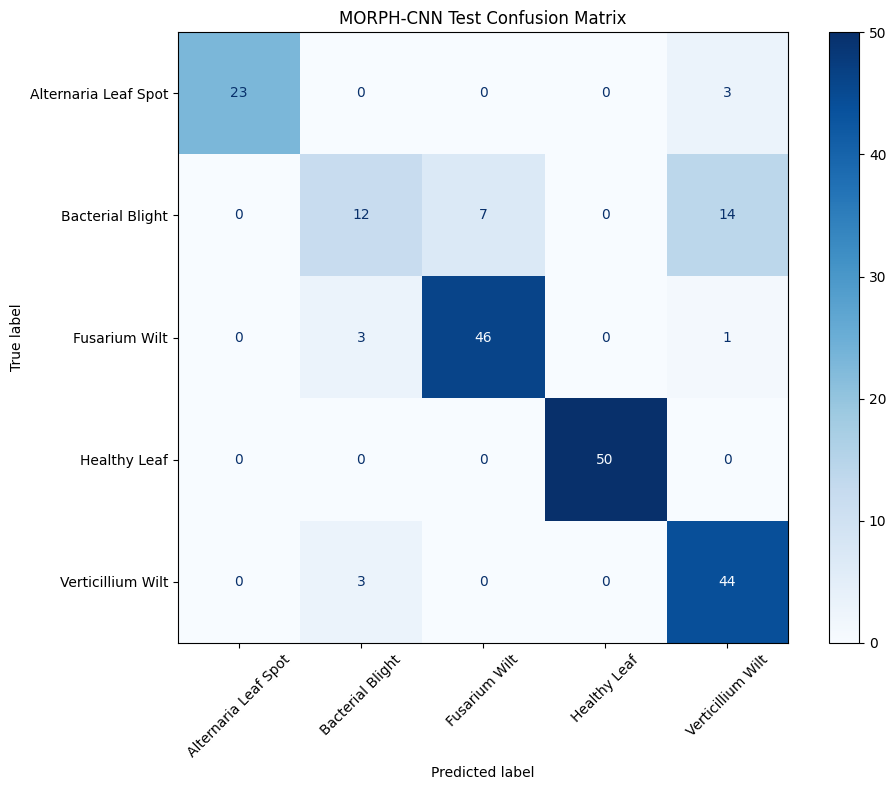


EVALUATION COMPLETED!
Metrics: E:\Cotton-Disease-Project\results\test_metrics.csv
Report: E:\Cotton-Disease-Project\results\classification_report.txt
Confusion Matrix: E:\Cotton-Disease-Project\results\confusion_matrix


In [3]:

# ==========================================
# MORPH-CNN: INDEPENDENT TEST EVALUATION
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. DATASET CONFIGURATION
# ==========================================

DATA_DIR = (
    PROJECT_DIR / "data" / "raw" /
    "Cotton_Original_Dataset"
)

RESULT_DIR = PROJECT_DIR / "results"
GRAPH_DIR = RESULT_DIR / "graphs"
CM_DIR = RESULT_DIR / "confusion_matrix"

for folder in [GRAPH_DIR, CM_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 16

# ==========================================
# 2. RECREATE ORIGINAL DATA SPLIT
# ==========================================

base_dataset = datasets.ImageFolder(str(DATA_DIR))

classes = base_dataset.classes
targets = np.array(base_dataset.targets)

indices = np.arange(len(targets))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=targets,
    random_state=SEED
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=targets[temp_idx],
    random_state=SEED
)

# ==========================================
# 3. TEST DATA TRANSFORMATION
# ==========================================

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_dataset_full = datasets.ImageFolder(
    str(DATA_DIR),
    transform=test_transform
)

test_data = Subset(
    test_dataset_full,
    test_idx
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_data))
print("Classes:", classes)

# ==========================================
# 4. LOAD TRAINED CHECKPOINT
# ==========================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

assert checkpoint["classes"] == classes, (
    "Checkpoint and dataset class order mismatch!"
)

model = MORPH_CNN(
    num_classes=len(classes)
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


print("Checkpoint loaded successfully!")
print("Best training epoch:", checkpoint["epoch"])

print("Available checkpoint keys:", checkpoint.keys())

if "best_val_acc" in checkpoint:
    print(
        "Best validation accuracy:",
        checkpoint["best_val_acc"] * 100
    )
elif "best_val_accuracy" in checkpoint:
    print(
        "Best validation accuracy:",
        checkpoint["best_val_accuracy"] * 100
    )
else:
    print("Validation accuracy key not found in checkpoint.")


# ==========================================
# 5. TEST PREDICTIONS
# ==========================================

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ==========================================
# 6. PERFORMANCE METRICS
# ==========================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("\n========== MORPH-CNN TEST RESULTS ==========")

print(f"Test Accuracy : {accuracy*100:.2f}%")
print(f"Macro Precision: {precision*100:.2f}%")
print(f"Macro Recall   : {recall*100:.2f}%")
print(f"Macro F1-score : {f1*100:.2f}%")

# ==========================================
# 7. CLASSIFICATION REPORT
# ==========================================

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print(report)

with open(
    RESULT_DIR / "classification_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# ==========================================
# 8. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(classes))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("MORPH-CNN Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    CM_DIR / "morph_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 9. SAVE TEST METRICS
# ==========================================

metrics_df = pd.DataFrame([{
    "Model": "MORPH-CNN",
    "Test_Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": f1,
    "Test_Images": len(test_data)
}])

metrics_df.to_csv(
    RESULT_DIR / "test_metrics.csv",
    index=False
)

print("\nEVALUATION COMPLETED!")
print("Metrics:", RESULT_DIR / "test_metrics.csv")
print("Report:", RESULT_DIR / "classification_report.txt")
print("Confusion Matrix:", CM_DIR)


In [7]:

import torch
import os
import sys

from pathlib import Path

PROJECT_DIR = Path(r"E:\Cotton-Disease-Project")

os.chdir(PROJECT_DIR)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Device initialization
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Check checkpoint
CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints" / "best_model.pth"
)

print("Device:", device)
print("Checkpoint exists:", CHECKPOINT_PATH.is_file())
print("Evaluation setup successful!")


Device: cpu
Checkpoint exists: True
Evaluation setup successful!
